# Spot graph formation
Builds one directed k-nearest-neighbour graph per fish / day / side from the spot centroids,
saves a plot of each, and compares the Day 1 and Day 2 graphs of the same operculum.

In [1]:
import os
import re

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from PIL import Image

## Configuration

In [ ]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "fish_ids.csv").is_file())
GROUP = "stressed"
DATA = ROOT / "data" / GROUP

IMAGES_DIR = DATA / 'images' / 'normalized_operculums'
LABELS_DIR = DATA / 'labels' / 'spots'
DISTANCE_CSV = DATA / 'spot_distances.csv'
OUTPUT_DIR = DATA / 'images' / ('directed_graphs' if DISTANCE_CSV.is_file() else 'directed_graphs_from_labels')

K_NEIGHBORS = 4
SHOW_PLOTS = False
DPI = 600

## Load spot polygons from the label files

In [19]:
NAME_RE = re.compile(r'fish_(\d+)_S_day(\d+)_id-\d+_([LR])_h')


def load_paths(directory):
    """{file name without extension: full path}"""
    return {os.path.splitext(f)[0]: os.path.join(directory, f) for f in sorted(os.listdir(directory))}


def parse_name(name):
    """'fish_10_S_day1_id-51_L_h' -> (10, 1, 'L')"""
    match = NAME_RE.fullmatch(name)
    if match is None:
        raise ValueError(f'Unexpected file name: {name}')
    fish, day, side = match.groups()
    return int(fish), int(day), side


def load_polygons(label_path, img_w, img_h):
    """One (N, 2) pixel-coordinate array per spot; spot id = line index in the label file."""
    polygons = []
    with open(label_path) as f:
        for line in f:
            values = line.split()[1:]
            if values:
                polygons.append(np.asarray(values, dtype=float).reshape(-1, 2) * (img_w, img_h))
    return polygons

In [ ]:
img_paths = load_paths(IMAGES_DIR)
lbl_paths = load_paths(LABELS_DIR)

unmatched = img_paths.keys() ^ lbl_paths.keys()
if unmatched:
    print('Images/labels without a counterpart (skipped):', sorted(unmatched))

sample_names = sorted(img_paths.keys() & lbl_paths.keys(),
                      key=lambda n: (parse_name(n)[0], parse_name(n)[2], parse_name(n)[1]))

spot_polygons = {}
for name in sample_names:
    img_w, img_h = Image.open(img_paths[name]).size
    spot_polygons[name] = load_polygons(lbl_paths[name], img_w, img_h)

print(f'{len(spot_polygons)} samples loaded')

## Spot-to-spot distance table
Uses the curated CSV when available. If it is missing, an equivalent table is computed from the
label centroids (note: this fallback does **not** apply the spot removals baked into the CSV).

In [21]:
def distance_table_from_labels(spot_polygons):
    """All-pairs centroid distances in the same layout as the distance CSV."""
    tables = []
    for name, polygons in spot_polygons.items():
        fish, day, side = parse_name(name)
        c = np.array([p.mean(axis=0) for p in polygons])
        n = len(c)
        i, j = np.divmod(np.arange(n * n), n)
        tables.append(pd.DataFrame({
            'Sample': fish, 'Day': day, 'Side': side, 'Spot_i': i, 'Spot_j': j,
            'Coords_i_x': c[i, 0], 'Coords_i_y': c[i, 1],
            'Coords_j_x': c[j, 0], 'Coords_j_y': c[j, 1],
            'Distance': np.linalg.norm(c[i] - c[j], axis=1),
        }))
    return pd.concat(tables, ignore_index=True)


if os.path.exists(DISTANCE_CSV):
    distance_data = pd.read_csv(DISTANCE_CSV)
else:
    print(f'WARNING: {DISTANCE_CSV} not found - computing distances from the label centroids instead.')
    distance_data = distance_table_from_labels(spot_polygons)

distance_data.head()

,Sample,Day,Side,Spot_i,Spot_j,Coords_i_x,Coords_i_y,Coords_j_x,Coords_j_y,Distance
0,31,1,L,0,0,403.441837,279.116326,403.441837,279.116326,0.000000
1,31,1,L,0,1,403.441837,279.116326,730.694949,576.644068,442.286510
2,31,1,L,0,2,403.441837,279.116326,902.612224,560.693898,573.111686
3,31,1,L,0,3,403.441837,279.116326,983.597060,328.432851,582.247543
4,31,1,L,0,4,403.441837,279.116326,303.487308,247.076974,104.963937


## Build and plot the directed k-NN graphs

In [22]:
def build_knn_digraph(df, k=K_NEIGHBORS):
    """Node per spot (id = spot number, pos = centroid); edge i -> j for the k nearest other spots of i."""
    G = nx.DiGraph()
    nodes = pd.concat([
        df[['Spot_i', 'Coords_i_x', 'Coords_i_y']].set_axis(['spot', 'x', 'y'], axis=1),
        df[['Spot_j', 'Coords_j_x', 'Coords_j_y']].set_axis(['spot', 'x', 'y'], axis=1),
    ]).drop_duplicates('spot')
    for spot, x, y in nodes.itertuples(index=False):
        G.add_node(int(spot), pos=(x, y))

    nearest = (df[df['Spot_i'] != df['Spot_j']]
               .sort_values('Distance', kind='stable')
               .groupby('Spot_i')
               .head(k))
    G.add_edges_from(zip(nearest['Spot_i'].astype(int), nearest['Spot_j'].astype(int)))
    return G


def plot_graph(G, title, save_path=None, show=SHOW_PLOTS):
    pos = {n: (x, -y) for n, (x, y) in nx.get_node_attributes(G, 'pos').items()}
    fig, ax = plt.subplots(figsize=(8, 8))
    nx.draw_networkx(G, pos, ax=ax, node_color='cyan', node_size=250,
                     edge_color='black', arrows=G.is_directed())
    ax.set_title(title)
    ax.set_aspect('equal')
    if save_path:
        fig.savefig(save_path, dpi=DPI)
    if show:
        plt.show()
    plt.close(fig)

In [23]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

graphs = {}
for (fish, day, side), df in distance_data.groupby(['Sample', 'Day', 'Side']):
    G = build_knn_digraph(df)
    graphs[(int(fish), int(day), side)] = G
    side_name = 'Left' if side == 'L' else 'Right'
    plot_graph(G, f'Fish {fish} - Day {day} - Spots Pattern - {side_name}',
               os.path.join(OUTPUT_DIR, f'Fish_{fish}_Day_{day}_Side_{side}.jpg'))

print(f'{len(graphs)} graphs built and saved to {OUTPUT_DIR}/')

184 graphs built and saved to directed_graphs/


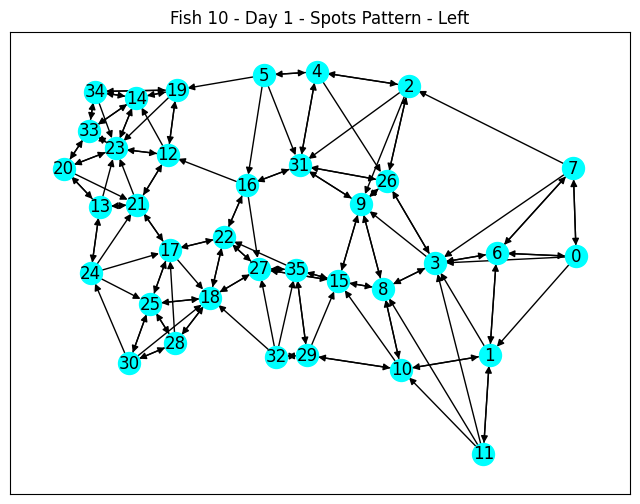

In [8]:
plot_graph(graphs[(10, 1, 'L')], 'Fish 10 - Day 1 - Spots Pattern - Left', show=True)

## Compare Day 1 vs Day 2 graphs

In [9]:
def spectral_distance(G1, G2):
    """Euclidean distance between the adjacency spectra (largest eigenvalues first, zero-padded).
    The undirected version is used so the adjacency matrix is symmetric and the eigenvalues are real."""
    spectra = [np.linalg.eigvalsh(nx.to_numpy_array(g.to_undirected()))[::-1] for g in (G1, G2)]
    n = max(len(s) for s in spectra)
    a, b = (np.pad(s, (0, n - len(s))) for s in spectra)
    return float(np.linalg.norm(a - b))


def approx_graph_edit_distance(G1, G2, timeout=30):
    """Exact GED is exponential in the number of nodes; this returns the best value found within
    `timeout` seconds (an upper bound on the true GED)."""
    return nx.graph_edit_distance(G1, G2, timeout=timeout)

In [10]:
comparison = pd.DataFrame([
    {'Sample': fish, 'Side': side,
     'Spots_day1': G1.number_of_nodes(), 'Spots_day2': graphs[(fish, 2, side)].number_of_nodes(),
     'Spectral_distance': spectral_distance(G1, graphs[(fish, 2, side)])}
    for (fish, day, side), G1 in graphs.items()
    if day == 1 and (fish, 2, side) in graphs
])
comparison

,Sample,Side,Spots_day1,Spots_day2,Spectral_distance
0,10,L,36,36,0.506088
1,10,R,21,21,0.365008
2,11,L,27,27,0.469468
3,11,R,18,18,0.312263
4,12,L,15,15,0.000000
5,12,R,22,22,0.000000
6,13,L,13,13,0.000000
7,13,R,12,12,0.000000
8,14,L,17,17,0.000000
9,14,R,15,15,0.512850


In [11]:
approx_graph_edit_distance(graphs[(10, 1, 'L')], graphs[(10, 2, 'L')], timeout=10)

np.float64(12.0)